In [3]:
import sys
from pathlib import Path

# Add src folder to Python path
sys.path.append(str(Path("..") / "DTE"))

from data_generator import DataGenerator
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from adbench.myutils import Utils


2026-01-11 17:12:10.645162: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-01-11 17:12:10.694683: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-11 17:12:11.520502: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
/usr/lib/python3/dist-packages/requests/__init__.py:87: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (4.0.0) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({}) doesn't match a supported "


In [11]:
datagenerator = DataGenerator(seed=0, test_size=0.5, normal=True)  # data generator
# Ensemble evaluation across ADBench datasets
for dataset_list in [datagenerator.dataset_list_classical, datagenerator.dataset_list_cv,
                         datagenerator.dataset_list_nlp]:
    for dataset in dataset_list:
        # import the dataset
        #print(f"name: {dataset}")
        datagenerator.dataset = dataset  # specify the dataset name
        data = datagenerator.generator(la=0, max_size=50000)  # maximum of 50,000 data points are available
        X = data['X_test']
        y = data['y_test']
        #print(dataset)

subsampling for dataset 34_smtp...
{'Samples': 50000, 'Features': 3, 'Anomalies': 21, 'Anomalies Ratio(%)': 0.04}
{'Samples': 1456, 'Features': 12, 'Anomalies': 50, 'Anomalies Ratio(%)': 3.43}
{'Samples': 6870, 'Features': 16, 'Anomalies': 156, 'Anomalies Ratio(%)': 2.27}
{'Samples': 5216, 'Features': 64, 'Anomalies': 150, 'Anomalies Ratio(%)': 2.88}
generating duplicate samples for dataset 15_Hepatitis...
{'Samples': 1000, 'Features': 19, 'Anomalies': 162, 'Anomalies Ratio(%)': 16.2}
generating duplicate samples for dataset 21_Lymphography...
{'Samples': 1000, 'Features': 18, 'Anomalies': 37, 'Anomalies Ratio(%)': 3.7}
{'Samples': 3062, 'Features': 166, 'Anomalies': 97, 'Anomalies Ratio(%)': 3.17}
{'Samples': 3686, 'Features': 400, 'Anomalies': 61, 'Anomalies Ratio(%)': 1.65}
generating duplicate samples for dataset 37_Stamps...
{'Samples': 1000, 'Features': 9, 'Anomalies': 79, 'Anomalies Ratio(%)': 7.9}
{'Samples': 7200, 'Features': 6, 'Anomalies': 534, 'Anomalies Ratio(%)': 7.42}
{'

In [4]:
datagenerator = DataGenerator(seed=0, test_size=0.5, normal=True)  # data generator
# Ensemble evaluation across ADBench datasets
for dataset_list in [datagenerator.dataset_list_classical, datagenerator.dataset_list_cv,
                         datagenerator.dataset_list_nlp]:
    for dataset in dataset_list:
        if dataset =="36_speech":   # plot for the data 36_speech
            print(f"name:{dataset}")
            datagenerator.dataset = dataset  # specify the dataset name
            data = datagenerator.generator(la=0, max_size=50000)  # maximum of 50,000 data points are available
            X = data['X_test']
            y = data['y_test']
            break



name:36_speech
{'Samples': 3686, 'Features': 400, 'Anomalies': 61, 'Anomalies Ratio(%)': 1.65}


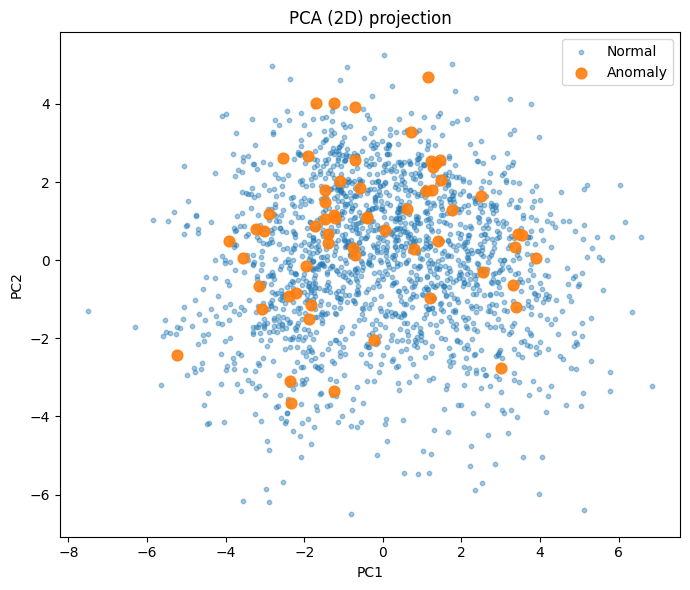

Explained variance ratio (PC1, PC2): [0.01341329 0.00921522]


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# X: (n, 400), y: (n,)
X = np.asarray(X)
y = np.asarray(y)

# Standardize is important when features have different scales
X_scaled = StandardScaler().fit_transform(X)

# Project to 2D
pca = PCA(n_components=2, random_state=0)
X_2d = pca.fit_transform(X_scaled)

normal = X_2d[y == 0]
anom   = X_2d[y == 1]

plt.figure(figsize=(7, 6))
plt.scatter(normal[:, 0], normal[:, 1], s=10, alpha=0.4, label="Normal")
plt.scatter(anom[:, 0],   anom[:, 1],   s=60, alpha=0.9, label="Anomaly")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA (2D) projection")
plt.legend()
plt.tight_layout()
plt.show()

print("Explained variance ratio (PC1, PC2):", pca.explained_variance_ratio_)


In [6]:
from matplotlib.patches import Ellipse

def plot_cov_ellipse(ax, mean, cov, nstd=2.5, **kwargs):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    width, height = 2 * nstd * np.sqrt(np.maximum(vals, 1e-12))
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    ell = Ellipse(mean, width, height, angle=angle, fill=False, linewidth=1.5, **kwargs)
    ax.add_patch(ell)



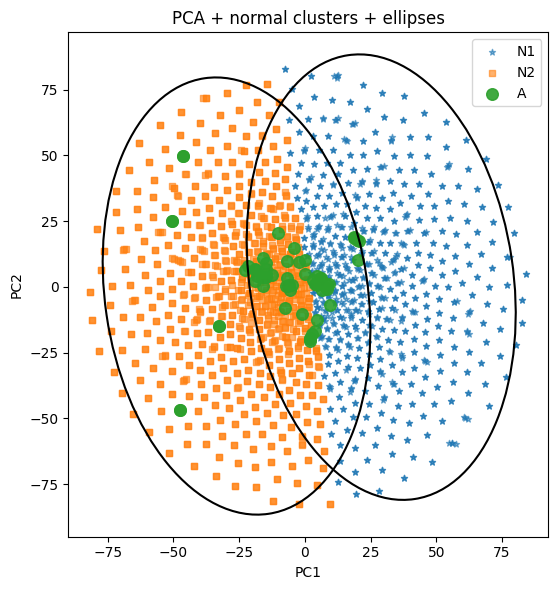

In [18]:
from sklearn.cluster import KMeans

# Use PCA output X_2d from above
normal = X_2d[y == 0]
anom   = X_2d[y == 1]

kmeans = KMeans(n_clusters=2, random_state=0, n_init="auto")
labels = kmeans.fit_predict(normal)

N1 = normal[labels == 0]
N2 = normal[labels == 1]

fig, ax = plt.subplots(figsize=(7, 6))

# normal clusters
ax.scatter(N1[:, 0], N1[:, 1], marker="*", s=20, alpha=0.6, label="N1")
ax.scatter(N2[:, 0], N2[:, 1], marker="s", s=20, alpha=0.6, label="N2")

# abnormal cluster
ax.scatter(anom[:, 0], anom[:, 1], marker="o", s=70, alpha=0.9, label="A")

plot_cov_ellipse(ax, N1.mean(axis=0), np.cov(N1, rowvar=False), nstd=2.5)
plot_cov_ellipse(ax, N2.mean(axis=0), np.cov(N2, rowvar=False), nstd=2.5)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA + normal clusters + ellipses")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


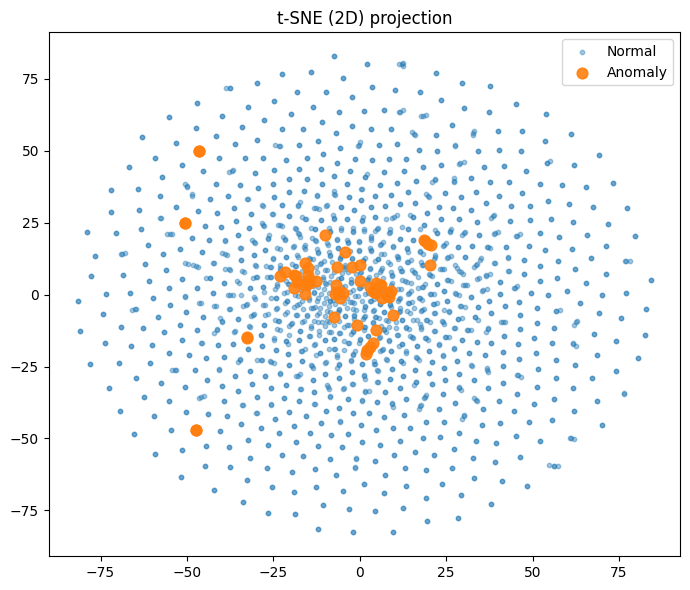

In [15]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=0)
X_2d = tsne.fit_transform(X_scaled)

plt.figure(figsize=(7, 6))
plt.scatter(X_2d[y == 0, 0], X_2d[y == 0, 1], s=10, alpha=0.4, label="Normal")
plt.scatter(X_2d[y == 1, 0], X_2d[y == 1, 1], s=60, alpha=0.9, label="Anomaly")
plt.title("t-SNE (2D) projection")
plt.legend()
plt.tight_layout()
plt.show()
